# AI651 PA2, Question 2: ConvLSTM on Moving MNIST ("Motion or Memory?")

This notebook runs the Question 2 pipeline end to end on the committed code in `src/`:

1. **Table 1 checks** (transforms and frame windows) and extra sanity checks.
2. **Data**: the fixed video-level split and the optical-flow statistics behind Figure 1.
3. **Models**: parameter counts for A–D, plus the Blank and Copy-last baselines.
4. **Training demo**: trains model A (seed 0) from scratch under the handout protocol and compares its loss curve with the committed run.
5. **Re-evaluation**: recomputes every test metric in the report from the committed checkpoints and checks it against the saved JSON.
6. **Tables and figures**: the report's results table, the model D screening, Figures 1–6, S1 and the GIFs.

The full write-up is in `../report/main.pdf`. The pipeline as separate scripts is listed in `../README.md`.
This notebook does not overwrite anything under `results/metrics/` or `checkpoints/`: the training demo writes to `checkpoints/notebook/` and `results/notebook/`, and Table 1 is checked in a temporary directory.

In [1]:
import json, os, subprocess, sys, tempfile, time
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display

from src import metrics as M
from src.data import SPLITS, get_split
from src.models import ArchConfig, Symmetrised, count_params
from src.registry import REGISTRY, build_model

pd.set_option("display.float_format", lambda v: f"{v:.4g}")
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("python", sys.version.split()[0], "| torch", torch.__version__, "| device", dev,
      torch.cuda.get_device_name(0) if dev == "cuda" else "")

python 3.12.3 | torch 2.9.0+cu128 | device cuda NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Table 1 checks

`checks.py` verifies the mirror and rotation transforms, the 1×/2×/3× input and target frames, the eight elements of the symmetry group, model A's parameter count (480,784), that Blank and Copy-last are exactly equivariant, and that the symmetrised wrapper is exactly consistent (gap ≤ 1e-10) even with random weights.

In [2]:
with tempfile.TemporaryDirectory() as tmp:
    r = subprocess.run([sys.executable, os.path.abspath("checks.py")], cwd=tmp, capture_output=True, text=True)
    t1 = json.load(open(os.path.join(tmp, "results/metrics/table1.json")))
assert r.returncode == 0, r.stdout + r.stderr
display(pd.DataFrame(t1["table1"]).set_index("row"))
print("extra checks:", json.dumps(t1["extra"], indent=1))
print("ALL PASS" if t1["all_pass"] else "FAILED")

,check,value,expected,pass
row,,,,
a,max|M(M(x))-x|,0,"0, equal",True
b,max|R^4(x)-x|,0,"0, equal",True
c,max|M R M(x)-R^-1(x)|,0,"0, equal",True
d,bright pixel of M(p),"[7, 10, 43]","[7, 10, 43]",True
e,bright pixel of R(p),"[7, 43, 10]","[7, 43, 10]",True
f,1x input / target frames,"[[1, 2, 3, 4, 5], [6, 7, 8, 9, 10]]","[[1, 2, 3, 4, 5], [6, 7, 8, 9, 10]]",True
g,2x input / target frames,"[[1, 3, 5, 7, 9], [11, 13, 15, 17, 19]]","[[1, 3, 5, 7, 9], [11, 13, 15, 17, 19]]",True
h,3x input / target frames,"[[1, 4, 7, 10, 13], [16, 19]]","[[1, 4, 7, 10, 13], [16, 19]]",True


extra checks: {
 "inverse_all_g": true,
 "8_distinct": true,
 "params_A": 480784,
 "params_A_ok": true,
 "blank_C_M": 0.0,
 "blank_C_R": 0.0,
 "copylast_C_M": 0.0,
 "copylast_C_R": 0.0,
 "sym_A_C_M": 7.742938340901597e-16,
 "sym_A_C_R": 4.631278105868199e-16
}
ALL PASS


## 2. Data and Figure 1

Moving MNIST (10,000 videos of 20 frames, 64×64) is split by video: 0–7,999 train, 8,000–8,999 validation, 9,000–9,999 test.
Figure 1 shows the per-step displacement of moving pixels (Farnebäck optical flow). It motivates the receptive-field "reach" argument: model A sees 8 px per step, so at 3× speed (about 3 × the median step) the digits move out of its reach.

train videos     0–7999  (8000 videos)
val   videos  8000–8999  (1000 videos)
test  videos  9000–9999  (1000 videos)


test tensor (1000, 20, 1, 64, 64) torch.uint8
flow statistics: {'n_videos': 50, 'n_pairs': 950, 'n_pixels_kept': 103050, 'median_speed': 3.3175023532887313, 'mean_speed': 3.271226112849784, 'speed_p10': 2.141907948804643, 'speed_p25': 2.999935388670475, 'speed_p75': 3.886223998792656, 'speed_p90': 4.123515172136713, 'speed_2x_median': 6.635004706577463, 'speed_3x_median': 9.952507059866194, 'direction_fractions': [0.049015041242115476, 0.04881125667151868, 0.06747210092188258, 0.07314895681707909, 0.06022319262493935, 0.056108685104318295, 0.026346433770014555, 0.032615235322658906, 0.03840853954391072, 0.08196991751576904, 0.0642212518195051, 0.05408054342552159, 0.06663755458515284, 0.06135856380397865, 0.057098495875788455, 0.03661329451722465, 0.04871421639980592, 0.07715672003881612], 'direction_min_fraction': 0.026346433770014555, 'direction_max_fraction': 0.08196991751576904}


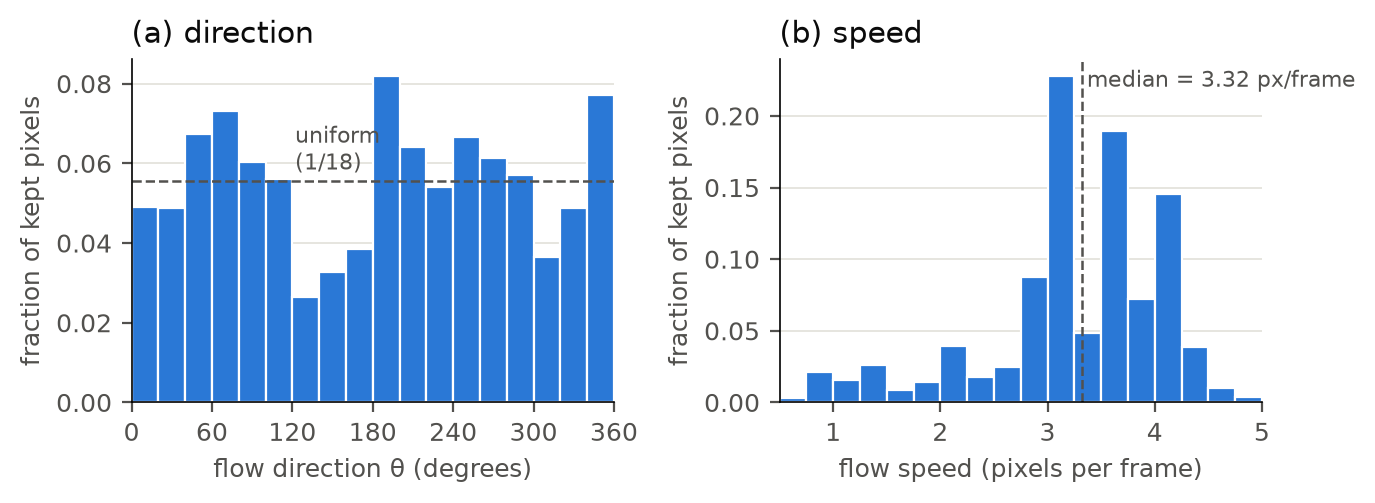

In [3]:
for name, (a, b) in SPLITS.items():
    print(f"{name:5s} videos {a:>5d}–{b - 1:<5d} ({b - a} videos)")
test = get_split("test", "data", dev)
print("test tensor", tuple(test.shape), test.dtype)
print("flow statistics:", json.load(open("results/metrics/flow_stats.json")))
display(Image("results/figures/fig1_flow.png", width=700))

## 3. Models

All learned models share the same ConvLSTM forecaster (`src/models.py`): two ConvLSTM layers without peepholes on a pixel-unshuffled frame, a sigmoid head, and a 9-step rollout that feeds its own predictions back (no teacher forcing). They differ in training data and folding:

| Model | Folding (reach per step) | Speed augmentation | Symmetry augmentation |
| --- | --- | --- | --- |
| A | 4×4 (8 px) | no | no |
| B | 4×4 (8 px) | no | yes |
| C | 4×4 (8 px) | yes | no |
| D | 8×8 (16 px) | yes | no |
| D+B | 8×8 (16 px) | yes | yes |

In [4]:
rows = []
for name, cfg in REGISTRY.items():
    m = build_model(name)
    rows.append(dict(model=name, **cfg["arch"].__dict__, params=count_params(m),
                     speed_aug=cfg["speed_aug"], sym_aug=cfg["sym_aug"]))
display(pd.DataFrame(rows).set_index("model"))
print(build_model("A"))

,patch,hidden,kernels,dilations,params,speed_aug,sym_aug
model,,,,,,,
A,4,64,"(3, 3)","(1, 1)",480784,False,False
B,4,64,"(3, 3)","(1, 1)",480784,False,True
C,4,64,"(3, 3)","(1, 1)",480784,True,False
D,8,64,"(3, 3)","(1, 1)",594496,True,False
DB,8,64,"(3, 3)","(1, 1)",594496,True,True


ConvLSTMForecaster(
  (cells): ModuleList(
    (0): ConvLSTMCell(
      (conv): Conv2d(80, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
    (1): ConvLSTMCell(
      (conv): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
  )
  (head): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1))
)


## 4. Training demo: model A, seed 0

`train.py` follows the handout protocol: 30 epochs, Adam, masked MSE on all five forecast horizons, one CPU random generator per seed. The demo writes to `checkpoints/notebook/` and leaves the committed checkpoint untouched. GPU kernels are not bit-for-bit deterministic, so the curve should track the committed run closely without matching it exactly.

In [5]:
t0 = time.time()
r = subprocess.run([sys.executable, "train.py", "--model", "A", "--seed", "0", "--tag", "notebook"],
                   capture_output=True, text=True)
assert r.returncode == 0, r.stdout[-2000:] + r.stderr[-2000:]
print("\n".join(r.stdout.strip().splitlines()[-6:]))
print(f"wall time {time.time() - t0:.0f} s")

epoch 26/30 loss 0.023451 time 6.4s
epoch 27/30 loss 0.023203 time 6.4s
epoch 28/30 loss 0.022828 time 6.4s
epoch 29/30 loss 0.022669 time 6.4s
epoch 30/30 loss 0.022367 time 6.4s
done: params 480784, 6.4 s/epoch
wall time 195 s


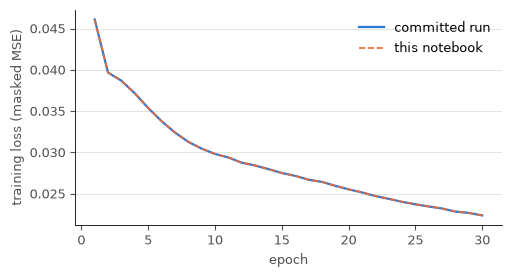

final loss: committed 0.02237, notebook 0.02237


In [6]:
import matplotlib.pyplot as plt
from src import plotstyle as ps

ps.apply_style()
new = json.load(open("results/notebook/runs/A_s0.json"))["epoch_loss"]
old = json.load(open("results/runs/A_s0.json"))["epoch_loss"]
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.plot(range(1, 31), old, color=ps.BLUE, lw=1.6, label="committed run")
ax.plot(range(1, 31), new, color=ps.ORANGE, lw=1.2, ls="--", label="this notebook")
ax.set_xlabel("epoch"); ax.set_ylabel("training loss (masked MSE)"); ax.legend(frameon=False)
plt.show()
print(f"final loss: committed {old[-1]:.5f}, notebook {new[-1]:.5f}")

## 5. Re-evaluation of every committed checkpoint (test split)

Each entry below is recomputed here from `checkpoints/*.pt` with `src/metrics.py` and compared with the saved `results/metrics/*_test.json` that the report's tables are built from.

- **E5 1×**: mean MSE over the five horizons at normal speed.
- **C_M, C_R**: consistency gaps under mirror and 90° rotation.
- **E2 k×**: mean MSE over the first two horizons at k× speed.

"sym" means the symmetrised forecaster (average over the 8 symmetries mapped back). It is exactly equivariant, so its gaps are float rounding (~1e-17).

In [7]:
def load(pred, seed=None, sym=False):
    f = build_model(pred)
    if seed is not None:
        ck = torch.load(f"checkpoints/{pred}_s{seed}.pt", map_location=dev)
        f = build_model(pred, ArchConfig.from_dict(ck["arch"]))
        f.load_state_dict(ck["state_dict"])
    f = f.to(dev).eval()
    return Symmetrised(f) if sym else f


def score(f):
    c = M.consistency(f, test)
    out = {"E5_1x": M.e_over(M.mse_per_video(f, test, 1), 5),
           "C_M": c["C_M"].mean().item(), "C_R": c["C_R"].mean().item()}
    for k in (1, 2, 3):
        out[f"E2_{k}x"] = M.e_over(M.mse_per_video(f, test, k), 2)
    return out


runs = [("blank", None, False), ("copylast", None, False)]
runs += [(p, s, False) for p in ("A", "B", "C", "D", "DB") for s in (0, 1)]
runs += [(p, s, True) for p in ("B", "D", "DB") for s in (0, 1)]
rows, worst = [], 0.0
t0 = time.time()
for pred, seed, sym in runs:
    stem = pred + ("_sym" if sym else "") + (f"_s{seed}" if seed is not None else "")
    new = score(load(pred, seed, sym))
    saved = json.load(open(f"results/metrics/{stem}_test.json"))
    for k, v in new.items():  # relative difference, with an absolute floor for the ~1e-17 gaps
        worst = max(worst, abs(v - saved[k]) / max(abs(saved[k]), 1e-6))
    rows.append(dict(run=stem, **new))
print(f"{len(runs)} runs re-evaluated in {time.time() - t0:.0f} s; "
      f"largest relative difference from the saved JSON: {worst:.1e}")
assert worst < 1e-3
per_run = pd.DataFrame(rows).set_index("run")
per_run

18 runs re-evaluated in 67 s; largest relative difference from the saved JSON: 0.0e+00


,E5_1x,C_M,C_R,E2_1x,E2_2x,E2_3x
run,,,,,,
blank,0.04256,0,0,0.04259,0.04251,0.04259
copylast,0.06408,0,0,0.05479,0.06607,0.07025
A_s0,0.02238,0.001791,0.00315,0.01882,0.04606,0.05367
A_s1,0.02164,0.001935,0.003087,0.01835,0.04614,0.05433
B_s0,0.02326,0.001059,0.001341,0.01954,0.04369,0.04902
B_s1,0.02141,0.001257,0.001509,0.01806,0.04407,0.04925
C_s0,0.02785,0.0008761,0.001795,0.02411,0.02956,0.03373
C_s1,0.02771,0.001161,0.002144,0.02356,0.02927,0.03377
D_s0,0.03062,0.0006057,0.001166,0.02853,0.03028,0.033


## 6. Results

### Seed-averaged test results

These are the numbers in the README and in the report's Tables 3–6: means over seeds 0 and 1, lower is better. The final model is **symmetrised D**.

In [8]:
def seed_mean(stem):
    return per_run.loc[[f"{stem}_s0", f"{stem}_s1"]].mean()

labels = {"A": "A (baseline)", "B": "B (+ symmetry aug.)", "C": "C (+ speed aug.)",
          "D": "D (8×8 folding + speed aug.)", "DB": "D+B", "B_sym": "symmetrised B",
          "D_sym": "symmetrised D (final)", "DB_sym": "symmetrised D+B"}
summary = pd.concat([per_run.loc[["blank", "copylast"]].rename(index={"blank": "Blank", "copylast": "Copy-last"}),
                     pd.DataFrame({labels[s]: seed_mean(s) for s in labels}).T])
summary

,E5_1x,C_M,C_R,E2_1x,E2_2x,E2_3x
Blank,0.04256,0,0,0.04259,0.04251,0.04259
Copy-last,0.06408,0,0,0.05479,0.06607,0.07025
A (baseline),0.02201,0.001863,0.003119,0.01859,0.0461,0.054
B (+ symmetry aug.),0.02233,0.001158,0.001425,0.0188,0.04388,0.04914
C (+ speed aug.),0.02778,0.001019,0.00197,0.02383,0.02941,0.03375
D (8×8 folding + speed aug.),0.02961,0.001217,0.001793,0.02763,0.02945,0.03192
D+B,0.03462,0.0002556,0.0003032,0.03375,0.03449,0.03571
symmetrised B,0.02175,8.634e-17,6.973e-17,0.01837,0.04313,0.04815
symmetrised D (final),0.02937,6.167e-17,4.777e-17,0.02751,0.02922,0.0317
symmetrised D+B,0.03451,2.963e-17,2.6e-17,0.03366,0.03442,0.03561


### Model D screening (validation split only)

Three candidates, each with 16 px reach and at most 721,176 parameters, were trained once (seed 0). The selection rule was fixed in advance: lowest mean validation E2 over 1×, 2× and 3×. The 8×8 folding (`p8`) won. The `k5` candidate never left the near-blank loss plateau (~0.040).

In [9]:
scr = json.load(open("results/metrics/d_screening.json"))
print("rule:", scr["rule"], "| winner:", scr["winner"])
pd.DataFrame(scr["candidates"]).T.drop(columns="arch")

rule: lowest mean validation E2 over 1x, 2x, 3x (seed 0) | winner: p8


,params,train_time_per_epoch_s,E5_1x,E2_1x,E2_2x,E2_3x,mean_E2
dil,480784,6.419,0.02981,0.02772,0.03104,0.03369,0.03082
k5,709520,9.975,0.03947,0.03949,0.03946,0.03946,0.03947
p8,594496,2.379,0.03037,0.02823,0.03006,0.03242,0.03024


### Figures

Figures 2–6 and S1 as they appear in the report (generated by `make_figures.py` and `plot_loss_curves.py`).

**Figure 2: model A (seed 0) on test videos 0 (overlapping digits), 6 and 7**

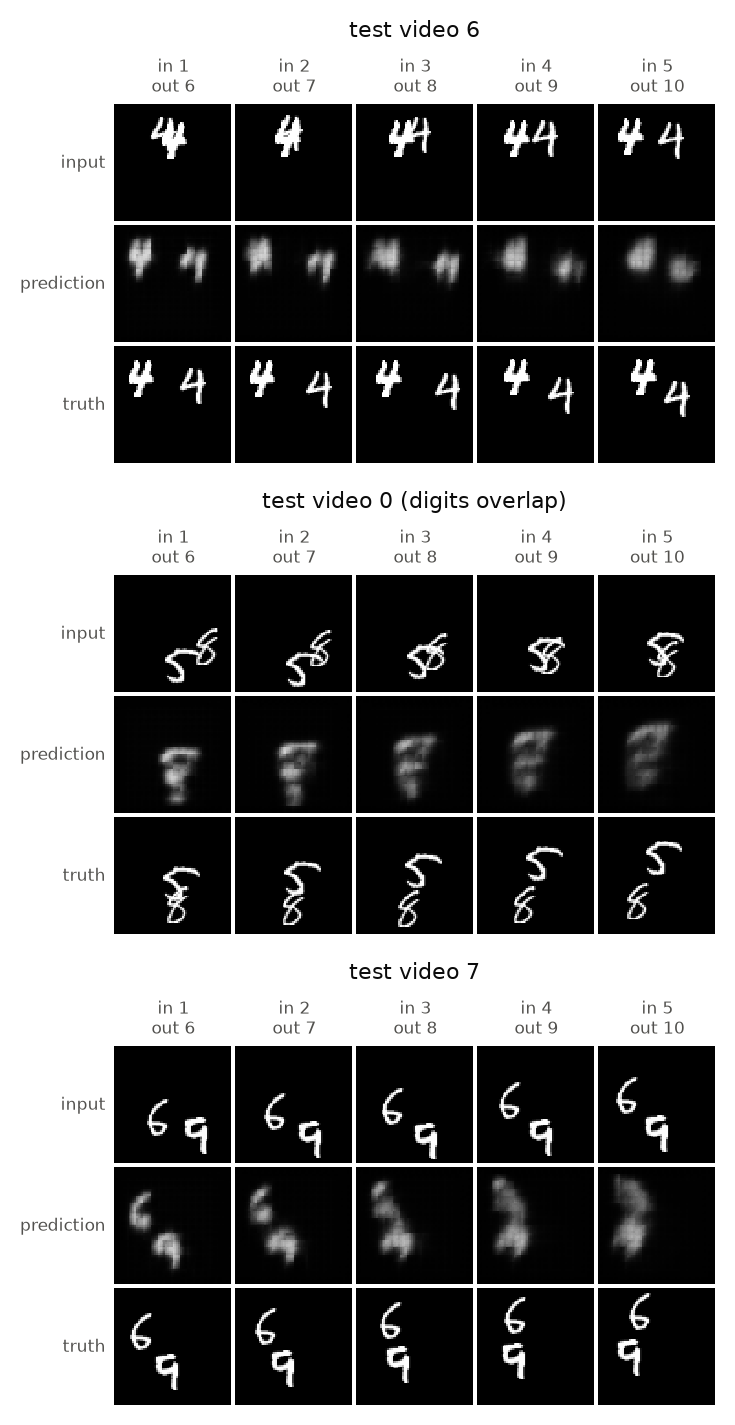

**Figure 3: model A on the two test videos with the largest C_M (mirror) and the two with the largest C_R (rotation)**

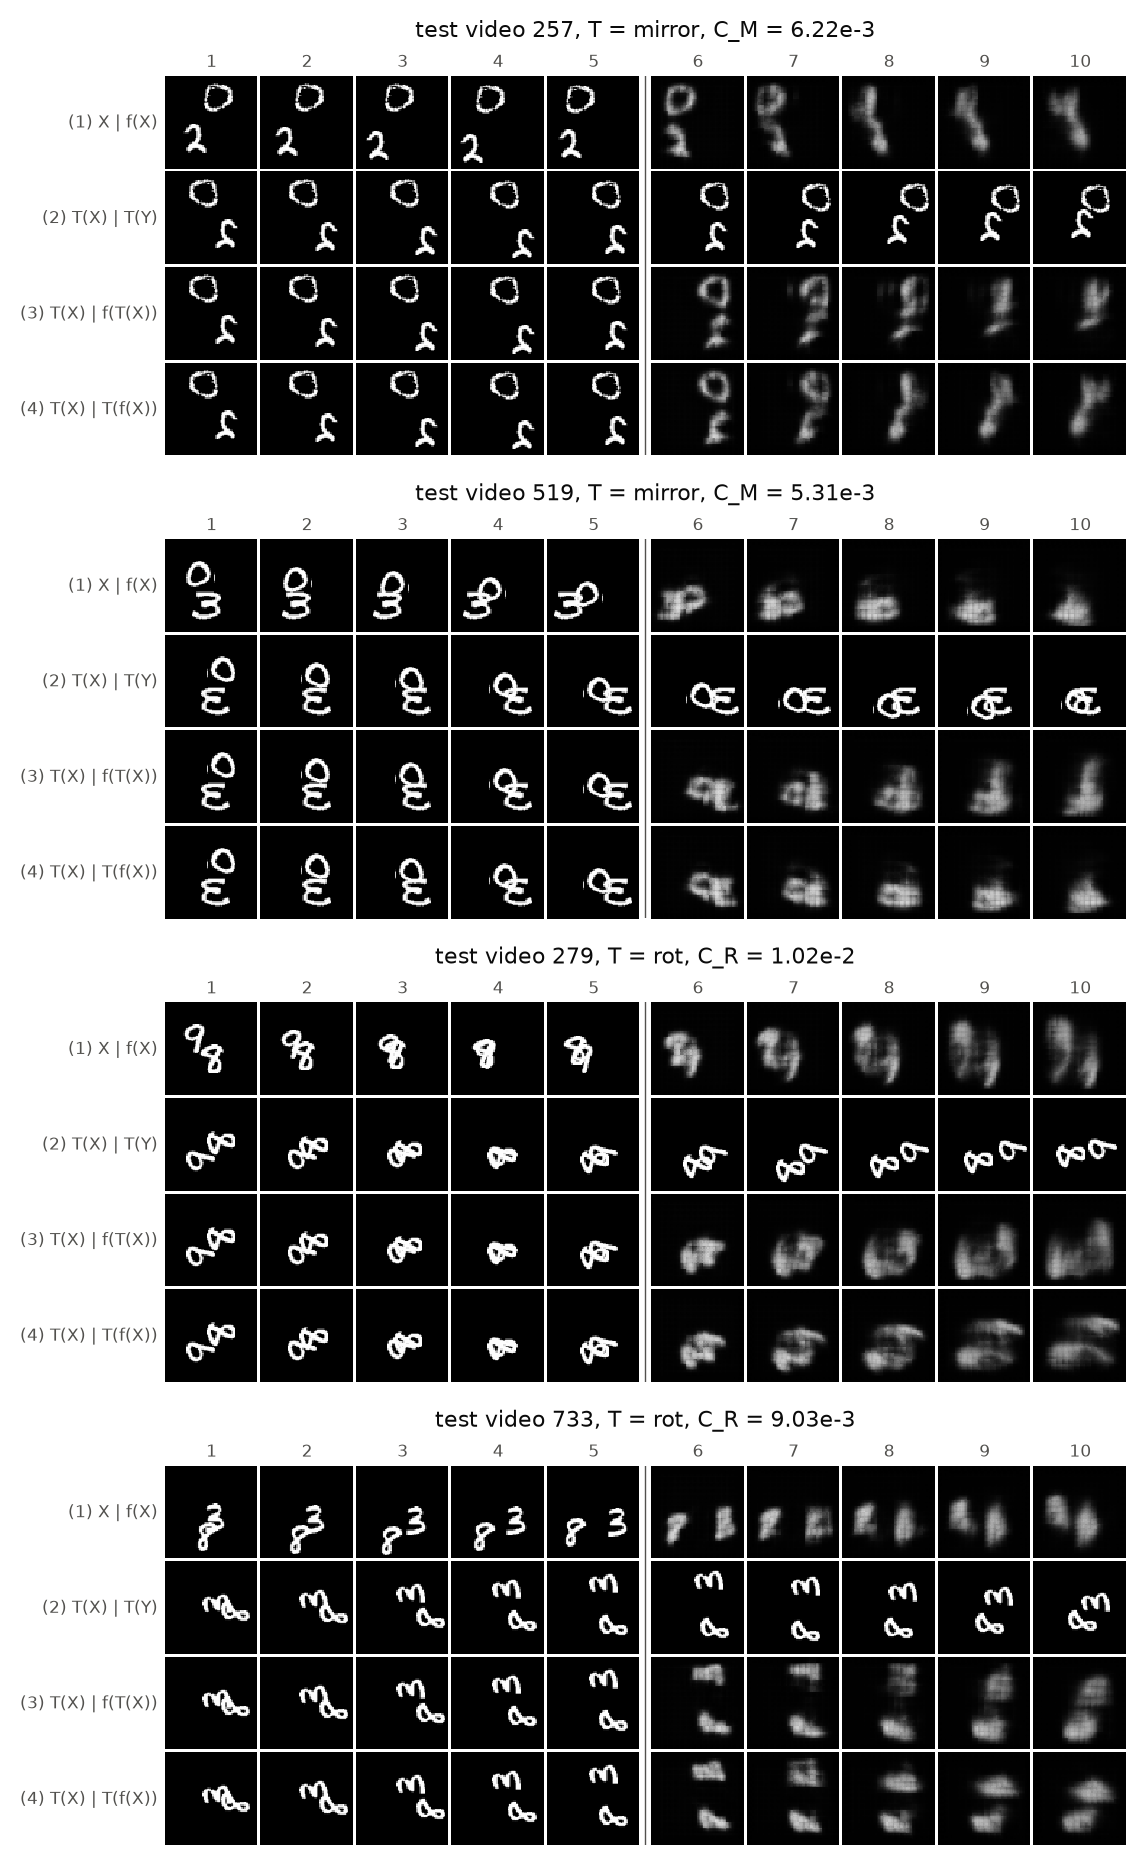

**Figure 4: per-video consistency gaps of model A**

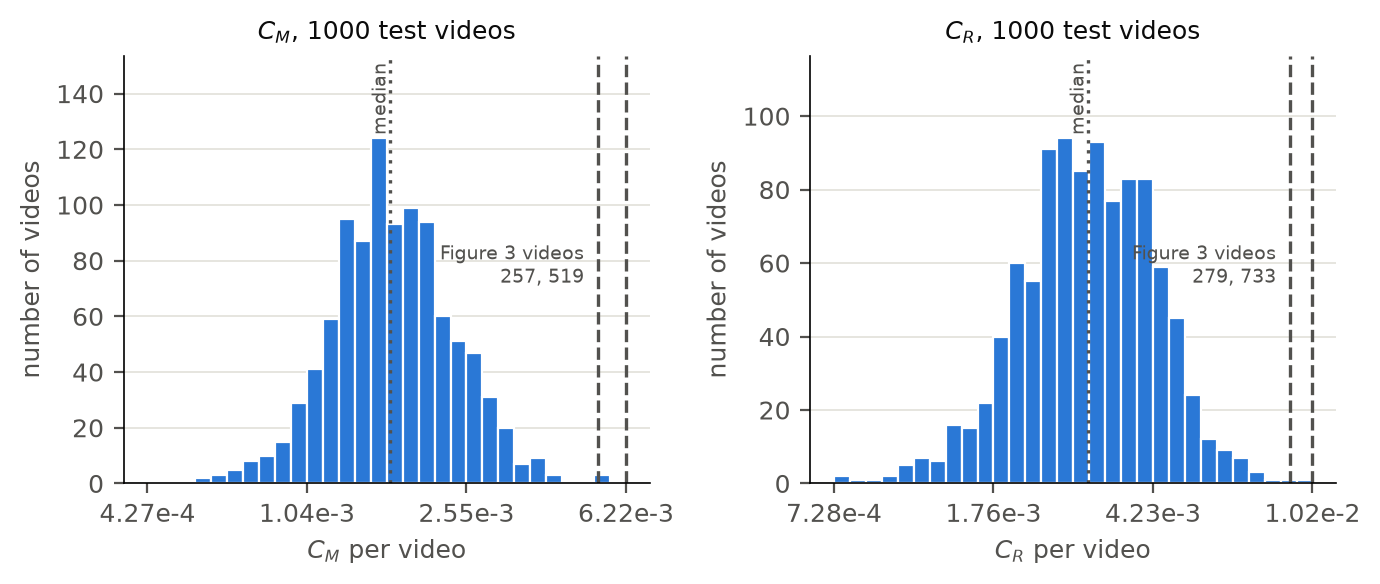

**Figure 5: model A on test video 29 at 1×, 2× and 3× speed**

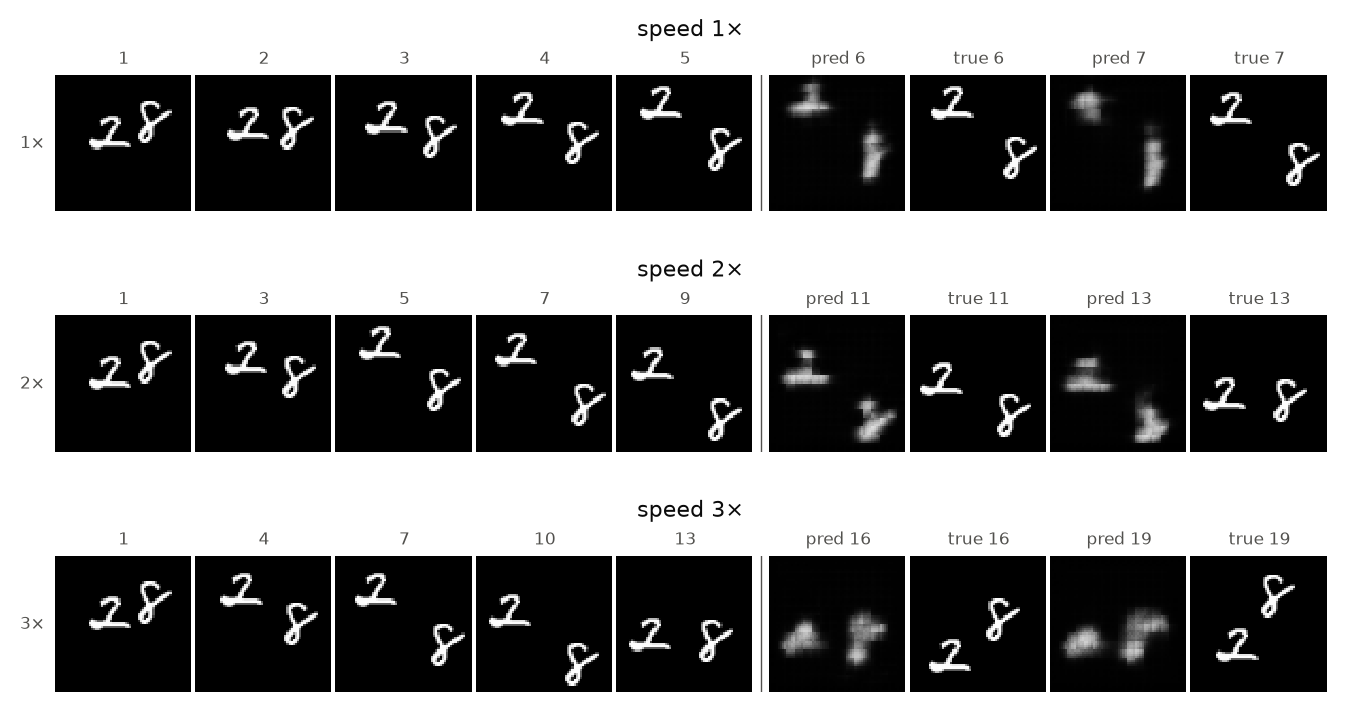

**Figure 6(a): the final model (symmetrised D) on the Figure 3 videos; rows 3 and 4 now coincide**

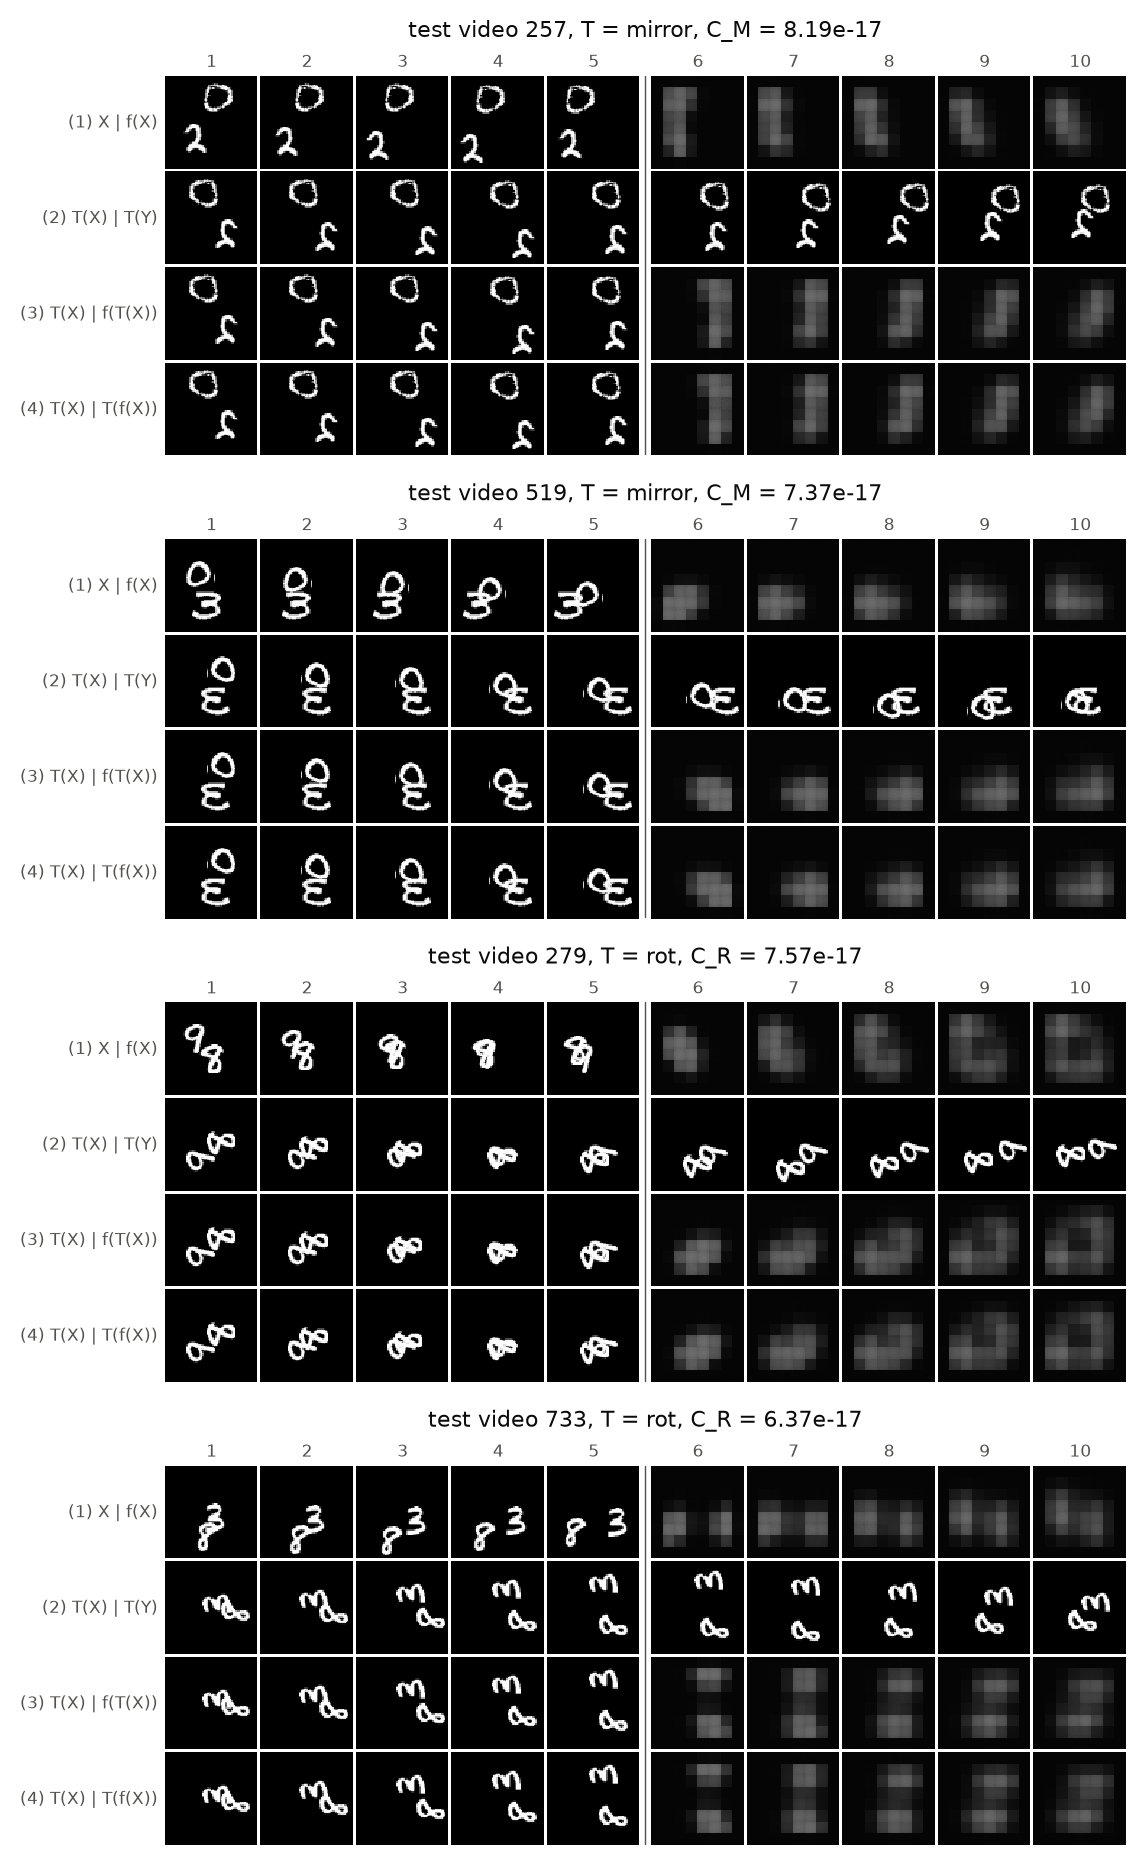

**Figure 6(b): the final model on test video 29 at 1×, 2× and 3× (Figure 5 repeated)**

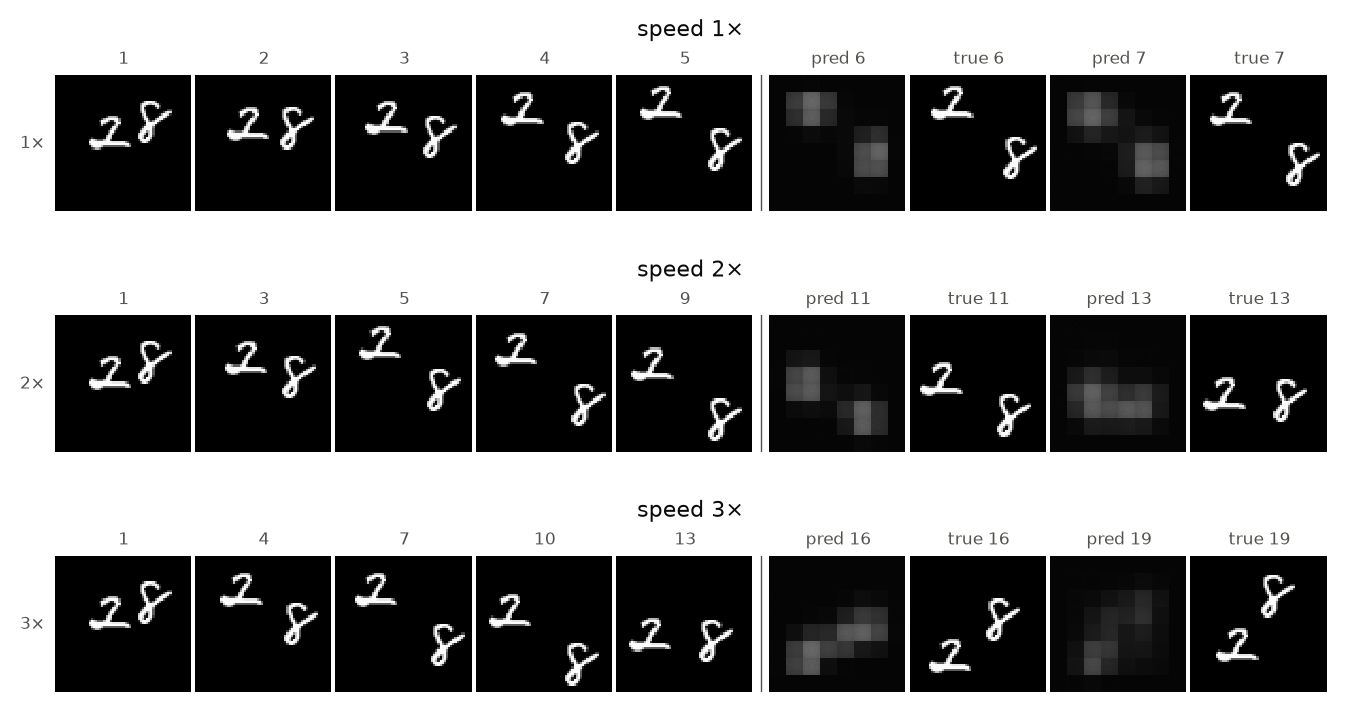

**Figure S1: training loss per epoch, every model and seed**

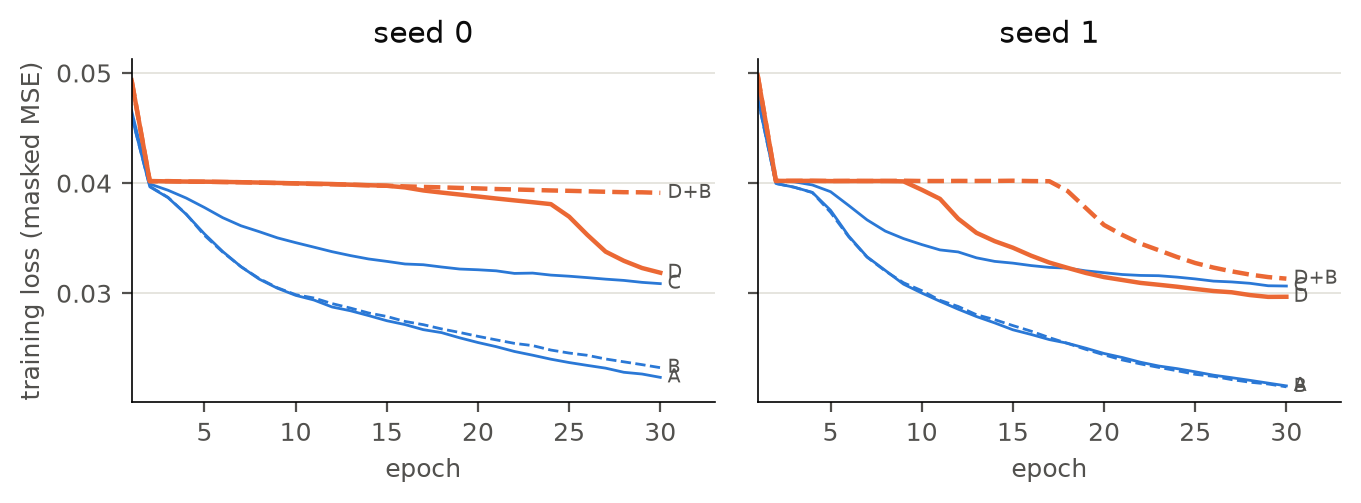

In [10]:
captions = {
    "fig2_examples": "Figure 2: model A (seed 0) on test videos 0 (overlapping digits), 6 and 7",
    "fig3_consistency": "Figure 3: model A on the two test videos with the largest C_M (mirror) and the two with the largest C_R (rotation)",
    "fig4_hist": "Figure 4: per-video consistency gaps of model A",
    "fig5_speeds": "Figure 5: model A on test video 29 at 1×, 2× and 3× speed",
    "fig6a_consistency": "Figure 6(a): the final model (symmetrised D) on the Figure 3 videos; rows 3 and 4 now coincide",
    "fig6a_speeds": "Figure 6(b): the final model on test video 29 at 1×, 2× and 3× (Figure 5 repeated)",
    "figS1_loss": "Figure S1: training loss per epoch, every model and seed",
}
for stem, cap in captions.items():
    display(Markdown(f"**{cap}**"))
    display(Image(f"results/figures/{stem}.png", width=760))

### GIFs

Each GIF steps through the five forecast horizons. Its four rows are those of Figure 3: (1) X and f(X), (2) T(X) and the true T(Y), (3) T(X) and f(T(X)), (4) T(X) and T(f(X)). An equivariant model makes rows 3 and 4 identical. Model A (left) and the final symmetrised D (right) on mirrored test video 257:


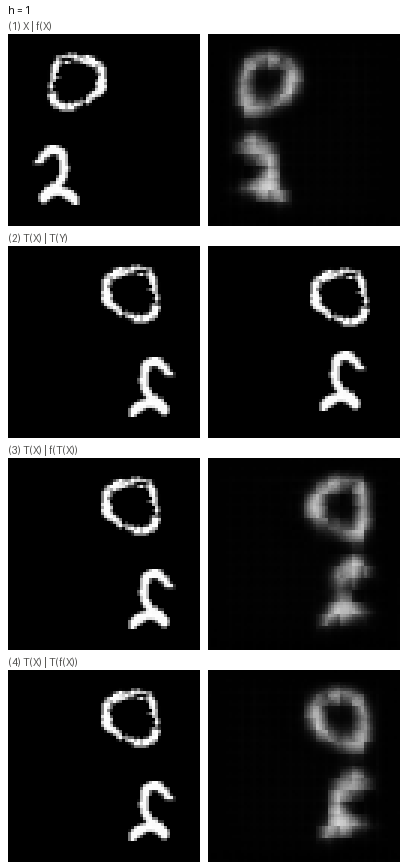
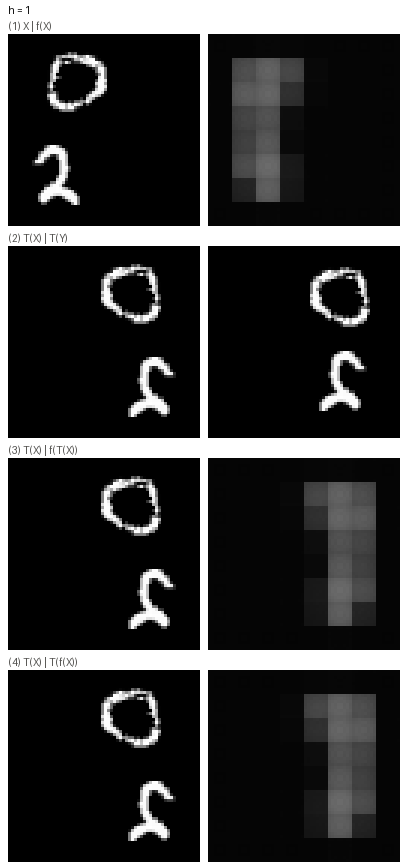

In [11]:
from IPython.display import HTML
import base64

def gif(path):
    return f'<img src="data:image/gif;base64,{base64.b64encode(open(path, "rb").read()).decode()}" width="340">'

HTML(f'<div style="display:flex;gap:16px">{gif("results/gifs/fig3_mirror_257.gif")}'
     f'{gif("results/gifs/fig6a_mirror_257.gif")}</div>')

## Findings

- **Mirror and rotation failures are about appearance.** Model A's rotation gap closes with symmetry augmentation (B), at no 1× cost. Exact consistency comes only from the symmetrised forecaster.
- **Speed failures are mostly about unfamiliar motion.** Speed augmentation alone (C, still 8 px reach) cuts 3× E2 from 0.054 to 0.034. Doubling the reach (D) helps a little more at 3× and makes the error nearly independent of speed.
- **The cost:** speed augmentation raises 1× error by about a quarter to a third (C +26%, D +35%).
- **Final model:** symmetrised D, which is exactly consistent under all 8 symmetries and the most speed-robust model. D+B was dropped because one of its seeds never left the early loss plateau (Figure S1).